In [1]:
from collections import defaultdict, deque
import math
import random
import matplotlib.pyplot as plt


It is possible to steal the art.


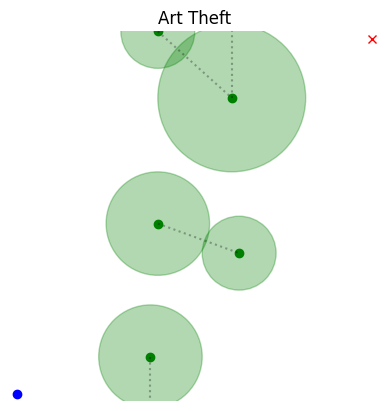

In [2]:
class Graph:
    def __init__(self):
        self.adj_list = defaultdict(list)
        self.visited = set()

    def add_edge(self, u, v):
        self.adj_list[u].append(v)
        self.adj_list[v].append(u)

    def BFS(self, start, forbidden_paths, blocked):
        queue = deque([start])
        self.visited.add(start)

        while queue:
            u = queue.popleft()
            for v in self.adj_list[u]:
                if v not in self.visited:
                    if (start, v) in forbidden_paths:
                        blocked.append(u)
                    self.visited.add(v)
                    queue.append(v)
        return True


def generate_random_sensors(m, n, k, radius_min, radius_max):
    return [[random.randint(0, m), random.randint(0, n), random.randint(radius_min, radius_max)] for _ in range(k)]


def plot_sensors(sensors, m, n, connections, blocked):
    _, ax = plt.subplots()
    ax.set_xlim(0, m)
    ax.set_ylim(0, n)

    for sensor in sensors:
        x, y, radius = sensor
        color = 'red' if (x, y) in blocked else 'green'
        circle = plt.Circle((x, y), radius, color=color, fill=True, alpha=0.3)
        ax.add_patch(circle)
        ax.plot(x, y, 'o', color=color)

    for u, v in connections:
        x1, y1 = u
        if isinstance(v, str):
            if v == 'left':
                x2, y2 = 0, y1
            elif v == 'right':
                x2, y2 = m, y1
            elif v == 'top':
                x2, y2 = x1, n
            elif v == 'bottom':
                x2, y2 = x1, 0
        else:
            x1, y1 = u
            x2, y2 = v

        plt.plot([x1, x2], [y1, y2], color='black',
                 linestyle='dotted', alpha=0.3)

    plt.title('Art Theft')
    plt.plot(1, 1, 'o', color='blue')
    plt.plot(m - 1, n - 1, 'x', color='red')
    plt.axis('off')
    plt.gca().set_aspect('equal', adjustable='box')
    plt.show()


def check_boundaries(sensor, m, n):
    x, y, radius = sensor
    connections = []
    if x - radius <= 0:
        connections.append('left')
    if x + radius >= m:
        connections.append('right')
    if y - radius <= 0:
        connections.append('bottom')
    if y + radius >= n:
        connections.append('top')
    return connections


def main():
    m, n, k = map(int, input(
        'Gallery dimension (M, N) and nº of sensors (k): ').split())
    radius_min, radius_max = map(int, input(
        'Min and max values for sensors\' radius length: ').split())

    sensors = generate_random_sensors(m, n, k, radius_min, radius_max)
    g = Graph()
    connections = []
    blocked = []
    path = []

    for i, sensor1 in enumerate(sensors):
        for j in range(i + 1, k):
            sensor2 = sensors[j]
            dist = math.hypot(sensor2[0] - sensor1[0], sensor2[1] - sensor1[1])
            if dist <= sensor1[2] + sensor2[2]:
                g.add_edge((sensor1[0], sensor1[1]), (sensor2[0], sensor2[1]))
                connections.append(
                    ((sensor1[0], sensor1[1]), (sensor2[0], sensor2[1])))

        boundary_connections = check_boundaries(sensor1, m, n)
        for boundary in boundary_connections:
            g.add_edge((sensor1[0], sensor1[1]), boundary)
            connections.append(((sensor1[0], sensor1[1]), boundary))
            path.append(boundary)

    forbidden_paths = [('left', 'bottom'), ('left', 'right'),
                       ('top', 'bottom'), ('top', 'right')]
    success = all(g.BFS(direction, forbidden_paths, blocked)
                  for direction in ['left', 'top'] if direction in path)

    if not success:
        print('It is not possible to steal the art.')
    else:
        print('It is possible to steal the art.')

    plot_sensors(sensors, m, n, connections, blocked)


if __name__ == '__main__':
    main()
